# Step 1: Setup Kaggle Notebook

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Step 2: Import Library.

In [1]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

CUDA available: True
Device name: Tesla T4


# Step 3: Cell pertama — cek GPU & install library.

In [2]:
!pip install -q ultralytics roboflow imagehash

from ultralytics import YOLO
import roboflow
print("Ultralytics & Roboflow ready")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.2 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 106.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 4.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics & Roboflow ready


# Step 4: Setup Roboflow API key sebagai secret (kalau belum) + download 2 dataset

In [3]:
from roboflow import Roboflow

rf = Roboflow(api_key="8aTqcvJxwVm5Wo3Ebl1f")

# Dataset 1: tube-iqa1l / tube-6xbjw (860 gambar)
project1 = rf.workspace("tube-iqa1l").project("tube-6xbjw")
version1 = project1.version(1)
dataset1 = version1.download("yolov11", location="/kaggle/working/dataset1")

# Dataset 2: kakaofriends-tube / tube-5iopq (909 gambar)
project2 = rf.workspace("kakaofriends-tube").project("tube-5iopq")
version2 = project2.version(1)
dataset2 = version2.download("yolov11", location="/kaggle/working/dataset2")

print("Dataset 1 path:", dataset1.location)
print("Dataset 2 path:", dataset2.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/dataset1 in yolov11:: 100%|██████████| 4136/4136 [00:00<00:00, 8833.48it/s]

loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/dataset2 in yolov11:: 100%|██████████| 4367/4367 [00:00<00:00, 9125.93it/s]

Dataset 1 path: /kaggle/working/dataset1
Dataset 2 path: /kaggle/working/dataset2


# Step 5: Cek struktur folder hasil download

In [4]:
import os

for name, ds in [("Dataset 1 (tube-6xbjw)", dataset1), ("Dataset 2 (tube-5iopq)", dataset2)]:
    print(f"\n=== {name} ===")
    print("Location:", ds.location)
    for root, dirs, files in os.walk(ds.location):
        level = root.replace(ds.location, "").count(os.sep)
        indent = "  " * level
        print(f"{indent}{os.path.basename(root)}/")
        if level < 2:
            for f in files[:3]:
                print(f"{indent}  {f}")
            if len(files) > 3:
                print(f"{indent}  ... ({len(files)} files total)")


=== Dataset 1 (tube-6xbjw) ===
Location: /kaggle/working/dataset1
dataset1/
  README.dataset.txt
  data.yaml
  README.roboflow.txt
  valid/
    images/
    labels/
  train/
    images/
    labels/
  test/
    images/
    labels/

=== Dataset 2 (tube-5iopq) ===
Location: /kaggle/working/dataset2
dataset2/
  README.dataset.txt
  data.yaml
  README.roboflow.txt
  valid/
    images/
    labels/
  train/
    images/
    labels/
  test/
    images/
    labels/


In [5]:
import os

for name in ['dataset1', 'dataset2']:
    print(f"\n{'='*50}\n{name}\n{'='*50}")
    base = f'/kaggle/working/{name}'
    for root, dirs, files in os.walk(base):
        level = root.replace(base, '').count(os.sep)
        indent = '  ' * level
        print(f'{indent}{os.path.basename(root)}/')
        subindent = '  ' * (level + 1)
        for f in files[:5]:  # limit biar ga kepanjangan
            print(f'{subindent}{f}')
        if len(files) > 5:
            print(f'{subindent}... ({len(files)} files total)')

    yaml_path = os.path.join(base, 'data.yaml')
    if os.path.exists(yaml_path):
        print(f"\n--- data.yaml ({name}) ---")
        with open(yaml_path) as f:
            print(f.read())


dataset1
dataset1/
  README.dataset.txt
  data.yaml
  README.roboflow.txt
  valid/
    images/
      toothpaste2222_jpg.rf.f9056c64c4e170002208e4166412be12.jpg
      tube-2024-05-17T134213-477_jpg.rf.65342411c599988501c18ea868f812f1.jpg
      Image_791_jpg.rf.f1467dcc7c7c0aa7e68a8cbf95310a03.jpg
      toothpaste2285_jpg.rf.e5f001654ed647bc7914086ccb8e50d1.jpg
      toothpaste23_jpg.rf.f56ab6b62e89ef505da770215f6d6ae7.jpg
      ... (172 files total)
    labels/
      IMG_0457_jpg.rf.babe77be416f14f3c6824ac5b764607d.txt
      tube-2024-05-17T134150-188_jpg.rf.c65c414c0952b8c582c0fab20801152c.txt
      toothpaste2213_jpg.rf.5a81d65c3858098118b89339cc146e57.txt
      SAM_1623_jpeg_jpg.rf.ccac559e00b344e9d0b0f8b072d95f62.txt
      ttt_jpeg_jpg.rf.610a5b33e25983b85f3ee97310e1b9ab.txt
      ... (172 files total)
  train/
    images/
      tube-2024-05-17T134234-638_jpg.rf.61b58791d4c116e758e749068cbfb15e.jpg
      tube-2024-05-22T231354-326_jpg.rf.b704d365edb9b37001d3eb2052a486a6.jpg
      I

**Step A — Merge kedua dataset ke satu folder**

In [6]:
import os, shutil

merged_base = '/kaggle/working/merged'
splits = ['train', 'valid', 'test']

for split in splits:
    os.makedirs(f'{merged_base}/{split}/images', exist_ok=True)
    os.makedirs(f'{merged_base}/{split}/labels', exist_ok=True)

sources = ['/kaggle/working/dataset1', '/kaggle/working/dataset2']
copied_count = {s: 0 for s in splits}
collision_count = 0

for src in sources:
    tag = os.path.basename(src)  # dataset1 / dataset2
    for split in splits:
        img_dir = f'{src}/{split}/images'
        lbl_dir = f'{src}/{split}/labels'
        if not os.path.exists(img_dir):
            continue
        for fname in os.listdir(img_dir):
            dst_img = f'{merged_base}/{split}/images/{tag}_{fname}'
            if os.path.exists(dst_img):
                collision_count += 1
                continue
            shutil.copy2(f'{img_dir}/{fname}', dst_img)
            copied_count[split] += 1

        for fname in os.listdir(lbl_dir):
            dst_lbl = f'{merged_base}/{split}/labels/{tag}_{fname}'
            shutil.copy2(f'{lbl_dir}/{fname}', dst_lbl)

print("Copied per split:", copied_count)
print("Filename collisions skipped:", collision_count)

# tulis data.yaml gabungan, class dinormalisasi jadi 'tube'
yaml_content = """train: train/images
val: valid/images
test: test/images

nc: 1
names: ['tube']
"""
with open(f'{merged_base}/data.yaml', 'w') as f:
    f.write(yaml_content)

print("\ndata.yaml gabungan sudah dibuat di:", f'{merged_base}/data.yaml')

Copied per split: {'train': 3711, 'valid': 354, 'test': 178}
Filename collisions skipped: 0

data.yaml gabungan sudah dibuat di: /kaggle/working/merged/data.yaml


**Step B — Dedupe pakai perceptual hash.**

In [7]:
import imagehash
from PIL import Image
import os
from collections import defaultdict

merged_base = '/kaggle/working/merged'
splits = ['train', 'valid', 'test']

# hitung hash tiap gambar
hash_to_files = defaultdict(list)
errors = []

for split in splits:
    img_dir = f'{merged_base}/{split}/images'
    for fname in os.listdir(img_dir):
        fpath = f'{img_dir}/{fname}'
        try:
            h = imagehash.phash(Image.open(fpath))
            hash_to_files[str(h)].append((split, fname))
        except Exception as e:
            errors.append((fpath, str(e)))

print(f"Total gambar diproses: {sum(len(v) for v in hash_to_files.values()) + len(errors)}")
print(f"Errors saat baca gambar: {len(errors)}")

# cari hash yang punya lebih dari 1 file (exact/near duplicate via phash)
duplicates = {h: files for h, files in hash_to_files.items() if len(files) > 1}
print(f"\nJumlah grup duplikat (phash sama persis): {len(duplicates)}")

# yang paling kritis: duplikat lintas split (train vs valid/test) -> data leakage risk
cross_split_dupes = []
for h, files in duplicates.items():
    split_set = set(s for s, f in files)
    if len(split_set) > 1:
        cross_split_dupes.append((h, files))

print(f"Grup duplikat LINTAS SPLIT (leakage risk): {len(cross_split_dupes)}")

print("\n--- Detail duplikat lintas split (max 20 ditampilkan) ---")
for h, files in cross_split_dupes[:20]:
    print(f"hash {h}: {files}")

# simpan full list ke file buat direview
with open('/kaggle/working/duplicate_report.txt', 'w') as f:
    f.write(f"Total duplicate groups: {len(duplicates)}\n")
    f.write(f"Cross-split duplicate groups: {len(cross_split_dupes)}\n\n")
    f.write("=== CROSS-SPLIT DUPLICATES (priority review) ===\n")
    for h, files in cross_split_dupes:
        f.write(f"{h}: {files}\n")
    f.write("\n=== SAME-SPLIT DUPLICATES ===\n")
    for h, files in duplicates.items():
        split_set = set(s for s, ff in files)
        if len(split_set) == 1:
            f.write(f"{h}: {files}\n")

print("\nFull report tersimpan di /kaggle/working/duplicate_report.txt")

Total gambar diproses: 4243
Errors saat baca gambar: 0

Jumlah grup duplikat (phash sama persis): 160
Grup duplikat LINTAS SPLIT (leakage risk): 69

--- Detail duplikat lintas split (max 20 ditampilkan) ---
hash ebb494497bb68449: [('train', 'dataset1_tube-2024-05-17T134226-138_jpg.rf.f9ba636eb22515edde5d64a65319e371.jpg'), ('valid', 'dataset1_tube-2024-05-17T134226-358_jpg.rf.958edd6dfdf0c51004c1434c5be96c5c.jpg')]
hash 84d0b3996d6616db: [('train', 'dataset1_tube-2024-05-17T134150-888_jpg.rf.1b7ba7fa5ae331e2da3bb02aa4297cbe.jpg'), ('test', 'dataset1_tube-2024-05-17T134150-972_jpg.rf.79898861fe1e396f89c9909d8c13bd1e.jpg')]
hash d9c63364c3996699: [('train', 'dataset1_tube-2024-05-17T134152-234_jpg.rf.d58980200a4d5074e4dd233ea0acb57f.jpg'), ('valid', 'dataset1_tube-20-_jpg.rf.245327f4a47832bb5347aaa85b91f162.jpg')]
hash 9cf379c6c0c63839: [('train', 'dataset1_tube-18-_jpg.rf.d48900361f7f4942a84fd91ae5a791fd.jpg'), ('test', 'dataset1_tube-17-_jpg.rf.920d4e0ee002355767402ebd6681af1f.jpg')]
h

In [8]:
import imagehash
from PIL import Image
import os
from collections import defaultdict

merged_base = '/kaggle/working/merged'
splits = ['train', 'valid', 'test']

# hitung ulang hash (biar konsisten, gak perlu load report.txt)
hash_to_files = defaultdict(list)
for split in splits:
    img_dir = f'{merged_base}/{split}/images'
    for fname in os.listdir(img_dir):
        fpath = f'{img_dir}/{fname}'
        try:
            h = imagehash.phash(Image.open(fpath))
            hash_to_files[str(h)].append((split, fname))
        except Exception:
            pass

duplicates = {h: files for h, files in hash_to_files.items() if len(files) > 1}

deleted_log = []
kept_log = []

for h, files in duplicates.items():
    split_set = set(s for s, f in files)
    if len(split_set) == 1:
        continue  # same-split duplicate, dibiarkan

    # tentukan split yang dipertahankan
    if 'train' in split_set:
        keep_split = 'train'
    elif 'valid' in split_set:
        keep_split = 'valid'
    else:
        keep_split = sorted(split_set)[0]

    for split, fname in files:
        if split == keep_split:
            kept_log.append((split, fname))
            continue
        # hapus image + label pasangannya
        img_path = f'{merged_base}/{split}/images/{fname}'
        label_fname = os.path.splitext(fname)[0] + '.txt'
        lbl_path = f'{merged_base}/{split}/labels/{label_fname}'

        if os.path.exists(img_path):
            os.remove(img_path)
        if os.path.exists(lbl_path):
            os.remove(lbl_path)
        deleted_log.append((split, fname, f'duplicate_of_{keep_split}'))

print(f"Total file dihapus (image+label): {len(deleted_log)}")
print(f"Total file dipertahankan (sisi lain dari cross-split dupe): {len(kept_log)}")

# hitung ulang jumlah per split setelah dedupe
print("\n--- Jumlah gambar per split SETELAH dedupe ---")
for split in splits:
    n = len(os.listdir(f'{merged_base}/{split}/images'))
    print(f"{split}: {n}")

# simpan log penghapusan
with open('/kaggle/working/dedupe_deleted_log.txt', 'w') as f:
    for split, fname, reason in deleted_log:
        f.write(f"{split}\t{fname}\t{reason}\n")

print("\nLog file yang dihapus tersimpan di /kaggle/working/dedupe_deleted_log.txt")

Total file dihapus (image+label): 69
Total file dipertahankan (sisi lain dari cross-split dupe): 70

--- Jumlah gambar per split SETELAH dedupe ---
train: 3711
valid: 317
test: 146

Log file yang dihapus tersimpan di /kaggle/working/dedupe_deleted_log.txt


In [9]:
from ultralytics import YOLO

# load base model pretrained (bukan train dari nol)
model = YOLO('yolo11n.pt')

results = model.train(
    data='/kaggle/working/merged/data.yaml',
    imgsz=640,
    epochs=100,
    patience=20,        # early stop kalau 20 epoch gak ada improvement
    save_period=10,      # checkpoint tiap 10 epoch (jaga-jaga Kaggle timeout)
    batch=16,             # aman untuk T4, bisa naikin ke 32 kalau VRAM cukup
    device=0,             # pakai GPU pertama (T4 x2 tersedia, kita pakai 1 dulu)
    project='/kaggle/working/runs',
    name='tube_detector_v1',
    exist_ok=True,
    verbose=True,
    plots=True,           # otomatis generate confusion matrix, PR curve, dll
)

print("\nTraining selesai!")
print(f"Best weights tersimpan di: /kaggle/working/runs/tube_detector_v1/weights/best.pt")
print(f"Last weights (checkpoint terakhir): /kaggle/working/runs/tube_detector_v1/weights/last.pt")

Ultralytics 8.4.155 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/merged/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=tube_detector_v1, nbs=64, nms=None, opset=N

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


      2/100      2.82G      1.453       1.71      1.734         55        640: 100% ━━━━━━━━━━━━ 232/232 8.4it/s 27.5s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 5.7it/s 1.7s.2s
                   all        317        527      0.515      0.512      0.465      0.273

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      2.82G      1.482       1.65      1.756         49        640: 100% ━━━━━━━━━━━━ 232/232 8.6it/s 27.1s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 5.7it/s 1.8s.2s
                   all        317        527      0.477      0.569      0.486      0.241

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/100      2.82G      1.426      1.571      1.713         51        640: 100% ━━━━━━━━━━━━ 232/232 8.4it/s 27.7s0.2ss
                 Class     Image

Step 1 — Cek results.png

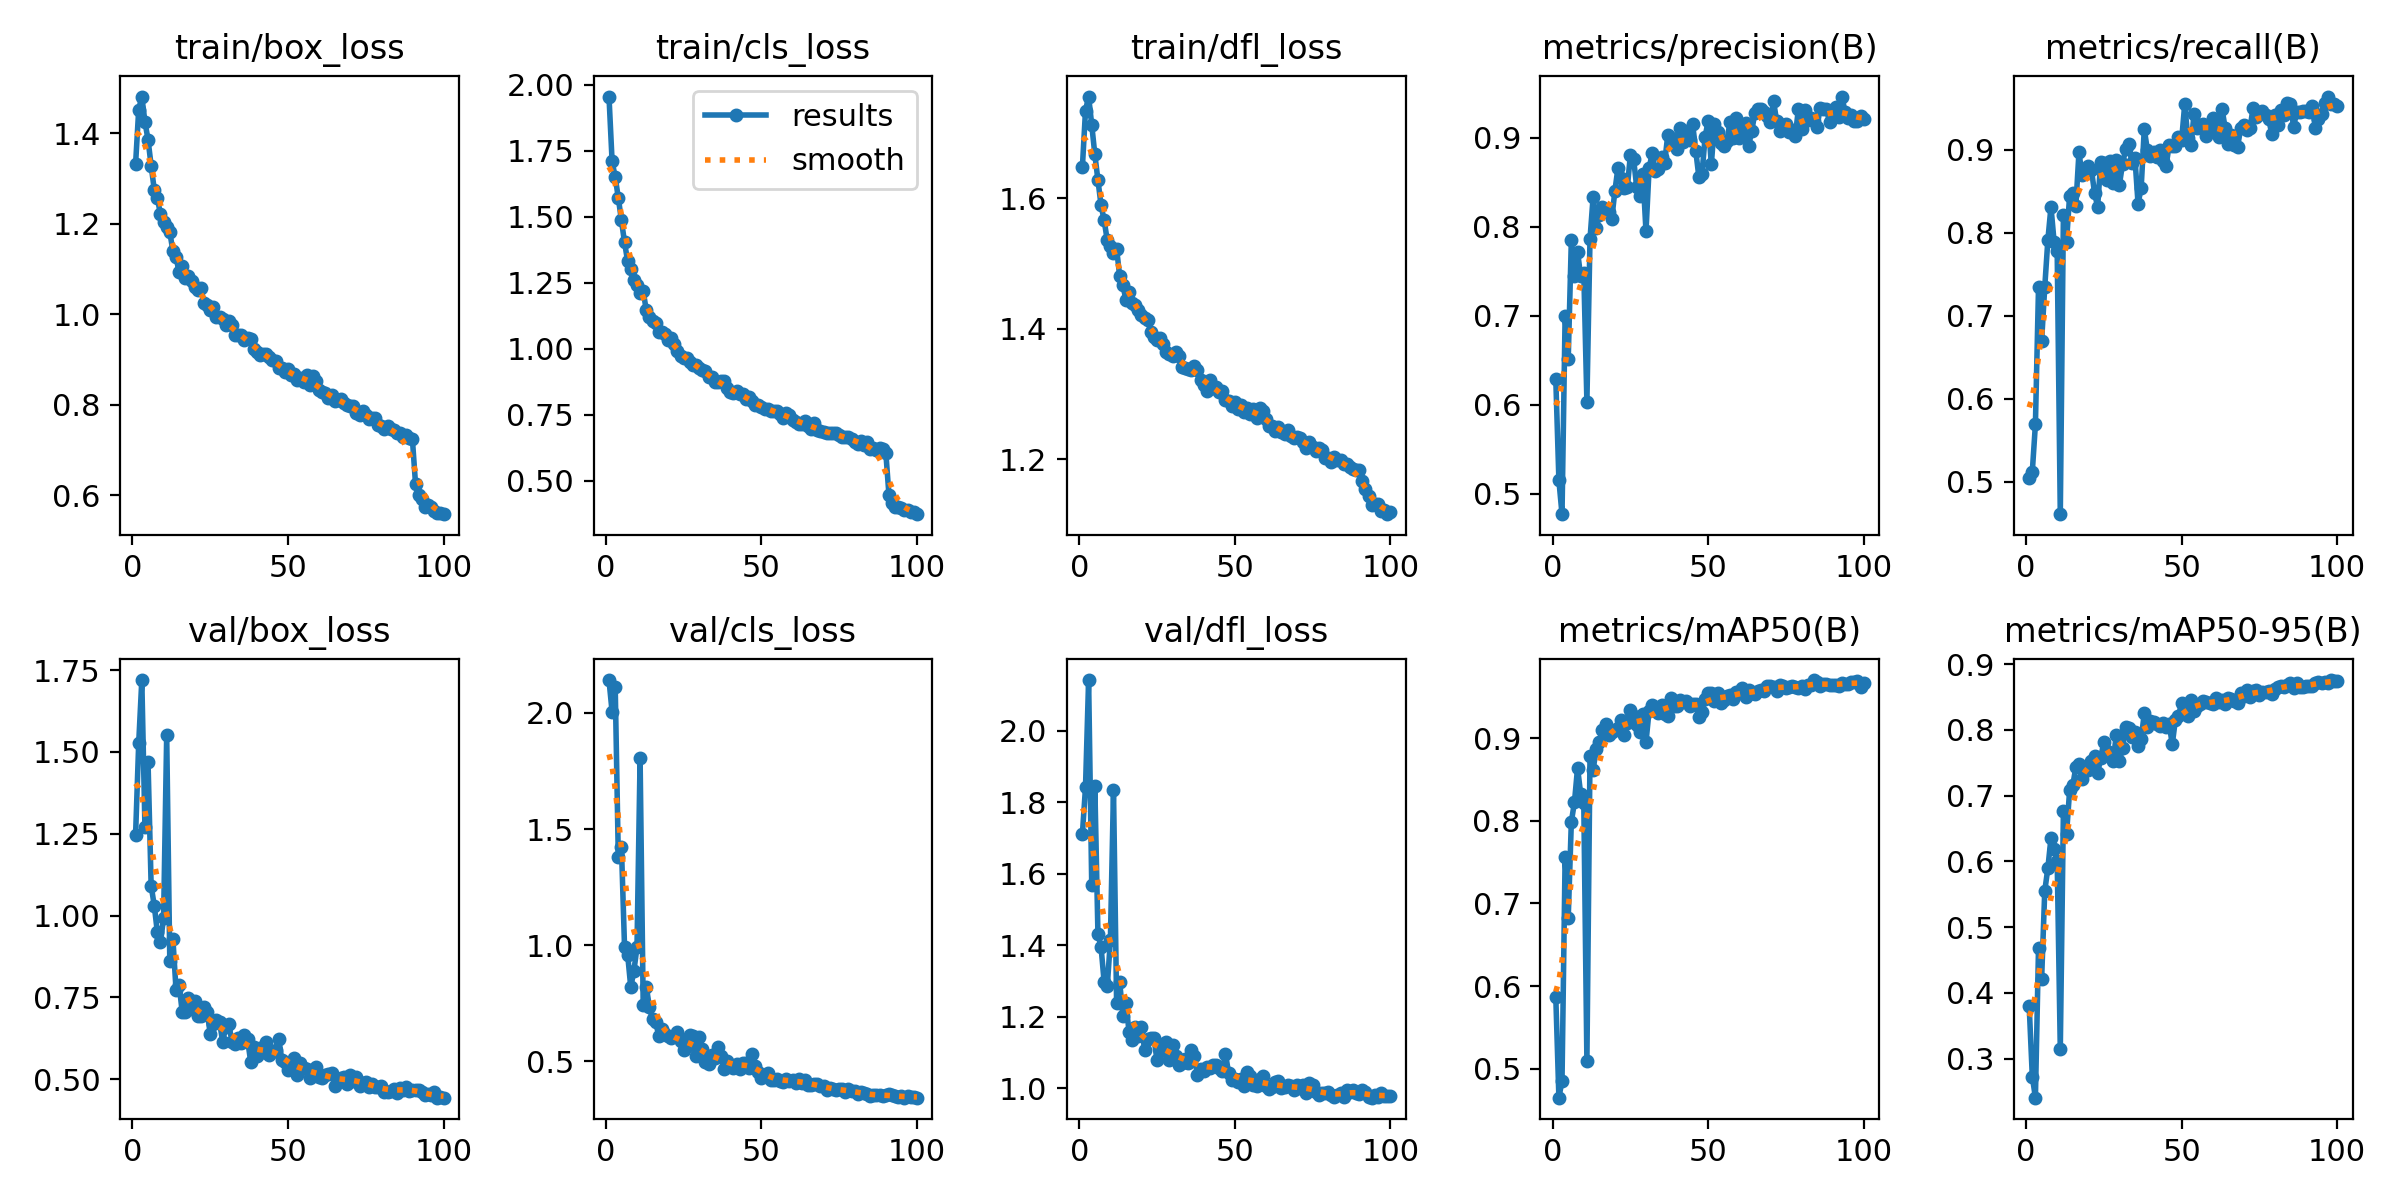

In [10]:
from IPython.display import Image
Image(filename='/kaggle/working/runs/tube_detector_v1/results.png')

In [13]:
import ipywidgets as widgets
from IPython.display import display, Image
from ultralytics import YOLO
import os

model = YOLO('/kaggle/working/runs/tube_detector_v1/weights/best.pt')

uploader = widgets.FileUpload(accept="image/*", multiple=True)
run_btn  = widgets.Button(description="Proses gambar", button_style="success")
out_area = widgets.Output()

def _files(u):
    v = u.value
    if not v: return []
    if isinstance(v, dict):
        return [(n, bytes(d["content"])) for n, d in v.items()]
    return [(d["name"], bytes(d["content"])) for d in v]

def _run(_):
    out_area.clear_output()
    with out_area:
        items = _files(uploader)
        if not items:
            print("Pilih gambar dulu lewat tombol di atas."); return
        for name, data in items:
            path = "/kaggle/working/_test_" + name.replace("/", "_")
            with open(path, "wb") as f:
                f.write(data)
            print("===", name, "===")

            results = model.predict(source=path, conf=0.25, save=True,
                                      project='/kaggle/working/inference_test', name='real_photos')
            r = results[0]
            print(f"Deteksi: {len(r.boxes)} tube, confidence: {[round(float(c),2) for c in r.boxes.conf]}")

            # FIX: pakai basename dari path yang disimpan, bukan nama asli
            saved_path = os.path.join(r.save_dir, os.path.basename(path))
            display(Image(filename=saved_path))

run_btn.on_click(_run)
display(uploader, run_btn, out_area)

FileUpload(value=(), accept='image/*', description='Upload', multiple=True)

Button(button_style='success', description='Proses gambar', style=ButtonStyle())

Output()